# K-Means Clustering for Smart Meter Customer Segmentation

In [37]:
import polars as pl
import glob
import numpy as np
import os
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import pandas as pd
from importlib import reload

from IPython.core.magic import register_cell_magic
@register_cell_magic
def skip(line, cell):
    return

from tslearn.clustering import TimeSeriesKMeans 
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Custom hyperparameter optimization module
from KMeans_Hyperparameters import optimize_kmeans

# Custom KMeans silhouette score module
import KMeans_Silhouette_score
from KMeans_Silhouette_score import validation_kMeans 
reload(KMeans_Silhouette_score)

# adjust to user environment
project_root = "/Users/jansigrist/Documents/SP/Customer_Segmentation_Lantern" 
sys.path.insert(0, project_root)

# Custom cluster statistics module
from Analysis import Cluster_Statistics
from Analysis.Cluster_Statistics import plot_cluster_percentiles
reload(Cluster_Statistics)

<module 'Analysis.Cluster_Statistics' from '/Users/jansigrist/Documents/SP/Customer_Segmentation_Lantern/Analysis/Cluster_Statistics.py'>

### 1. CONFIGURATION: Dataset selection and hyperparameters

In [38]:
# Define analysis scope: SWW/GroupE datasets, building types, clusters

dataset = "SWW"  # Options: "SWW", "GroupE"
building_type = "flat" # "flat", "house", "all"
number_of_clusters = 3  # Optimal k from silhouette analysis

print(f"Dataset: {dataset}, Building: {building_type}, k={number_of_clusters}")

Dataset: SWW, Building: flat, k=3


### 2. TIME SERIES DATA: Load hourly smart meter consumption (96 timestamps = 1 day)

In [39]:
# Load normalized hourly averaged data into 3D numpy array

n_timestamps = 96

# Adjust 'SM_DATA_hourlyAveraged_normalized' to handle different time scales if needed 
# Check preprocessing scripts for available options
input_folder = Path(f"{project_root}/DATA/{dataset}/SM_DATA_hourlyAveraged_normalized")

# Pattern to match CSV data files
pattern = str(input_folder / "*.csv")
file_paths = glob.glob(pattern)

data_list = []
filename_list = []

# Iterate over each file, read data, and reshape into 3D array
for file_path in file_paths:
    df = pl.read_csv(file_path)

    base = os.path.basename(file_path)  # e.g., "10030.csv"
    resid, _ = os.path.splitext(base)  # "10030"

    # Ensure the DataFrame has the expected number of timestamps
    if len(df) != n_timestamps:
        continue

    values_array = (
        df["day_avg_bruttolastgang_kwh"]
        .to_numpy()
        .reshape((1, n_timestamps, 1))
    )
    data_list.append(values_array)
    filename_list.append(resid)

if data_list:
    data_3d = np.concatenate(data_list, axis=0)
    print(f"Shape of the 3D array: {data_3d.shape}")
    train_data = data_3d
else:
    train_data = None
    print("No matching files with correct length found.")

Shape of the 3D array: (1481, 96, 1)


### 3. SURVEY DATA: Load dwelling type and resident id from survey

In [40]:
# Load survey data and extract relevant columns: resident_id and Building Type

file_path = f"{project_root}/DATA/{dataset}/Survey_Data/Survey_Data_{dataset}.xlsx"

# Read Excel file with appropriate parameters based on dataset
if dataset == "SWW":
    df = pd.read_excel(
        file_path,
        skiprows=4,
        nrows=1500,
        header=None,
        dtype={10: str, 142: str}, # Columns as string
    )
    cols_to_extract = [10, 142]
elif dataset == "GroupE":
    df = pd.read_excel(
        file_path,
        skiprows=3,
        nrows=1500,
        header=None,
        dtype={0: str, 148: str}, # Columns as string
    )
    cols_to_extract = [0, 148]

# Extract relevant columns and rename
extracted_df = df.iloc[:, cols_to_extract].copy()
extracted_df.columns = ["resident_id", "building_type"]

# Check for duplicate resident_id entries
total_rows = len(extracted_df)
unique_resident_ids = extracted_df["resident_id"].nunique()

print(f"Total rows: {total_rows}")
print(f"Unique resident_id count: {unique_resident_ids}")

if total_rows > unique_resident_ids:
    print(f"There are {total_rows - unique_resident_ids} duplicate resident_id entries.")
else:
    print("No duplicate resident_id entries found.")

# Merge filename list with extracted survey data
order_df = pd.DataFrame({"resident_id": filename_list})
category_df = order_df.merge(extracted_df, on="resident_id", how="left")

# Filter valid households (exclude "No Information" + wrong building type)
rows_to_keep_indices = []
exclude_building_type = building_type

if building_type == "all":
    exclude_building_type = None
elif building_type == "house":
    exclude_building_type = "Flat"
elif building_type == "flat":
    exclude_building_type = "House"

if building_type != "all":
    for i, row in category_df.iterrows():
        # Check if 'No Information' NOT in any value of that row
        if "No Information" not in row.values:
            # Check if 'Flat' NOT in any value of that row
            if exclude_building_type not in row.values:
                rows_to_keep_indices.append(i)
else:
    for i, row in category_df.iterrows():
        rows_to_keep_indices.append(i)

train_data = train_data[rows_to_keep_indices, :, :]

print(f"Number of samples after cleaning: {train_data.shape[0]}")

filename_list = [filename_list[i] for i in rows_to_keep_indices]

Total rows: 1500
Unique resident_id count: 1499
There are 1 duplicate resident_id entries.
Number of samples after cleaning: 801


### 4. VALIDATION: Find optimal cluster number and hyperparameters from Silhouette score analysis

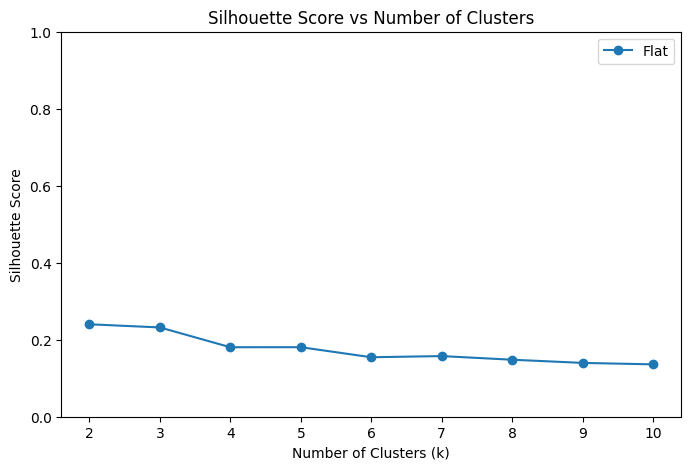


Best combination of hyperparameters:
n_clusters                  3
init                k-means++
n_init                      1
max_iter                  100
silhouette_score     0.231897
db_score             1.354532
Name: 0, dtype: object
Silhouette Score: 0.2318971926610931 for k=3
Davies-Bouldin Score: 1.3545318000119069 for k=3


In [41]:
# Validate KMeans clustering

# Plot Silhouette scores for KMeans clustering across different k values using custom module
validation_kMeans(project_root, train_data, train_data, dataset, building_type)

# Optimize KMeans hyperparameters via custom grid search module
optimize_kmeans(train_data)

# Final KMeans clustering and evaluation using previously determined optimal k
kmeans = TimeSeriesKMeans(n_clusters=number_of_clusters,max_iter=500, verbose=False, random_state=42,n_init=2, n_jobs=-1)
labels_clusters = kmeans.fit_predict(train_data.reshape((train_data.shape[0], train_data.shape[1])))
sh = silhouette_score(train_data.reshape((train_data.shape[0], train_data.shape[1])), labels_clusters)
db = davies_bouldin_score(train_data.reshape((train_data.shape[0], train_data.shape[1])), labels_clusters)
print(f"Silhouette Score: {sh} for k={number_of_clusters}")
print(f"Davies-Bouldin Score: {db} for k={number_of_clusters}")

### 5. K-MEANS CLUSTERING: Optimal k from silhouette analysis

In [ ]:
# KMeans clustering with optimized parameters

max_iterations = 300 # from hyperparameter optimization
n_init = 3 # from hyperparameter optimization

kmeans = TimeSeriesKMeans(n_clusters=number_of_clusters, max_iter=max_iterations, verbose=False, random_state=42,n_init=n_init, n_jobs=-1)
clusters_train = kmeans.fit_predict(train_data)

### 6. RESULTS EXPORT: Cluster assignments with household IDs

In [43]:
# saves the found clusters in a csv file with the corresponding household IDs

# Convert filename_list items to strings
resident_ids = [str(h) for h in filename_list]

# Creates Polars DataFrame with house IDs and clusters
result_df = pl.DataFrame({
    "resident_id": resident_ids,
    "cluster": clusters_train + 1
}).sort("cluster")

result_df.write_csv(f"{project_root}/Results/{dataset}/DATA/Cluster/hourly_avg_clustering_kMeans_{building_type}_{'technical'}.csv")

### 7. ANALYSIS: Visualization of consumption profiles, statistical analysis, PAR calculation, distribution of features

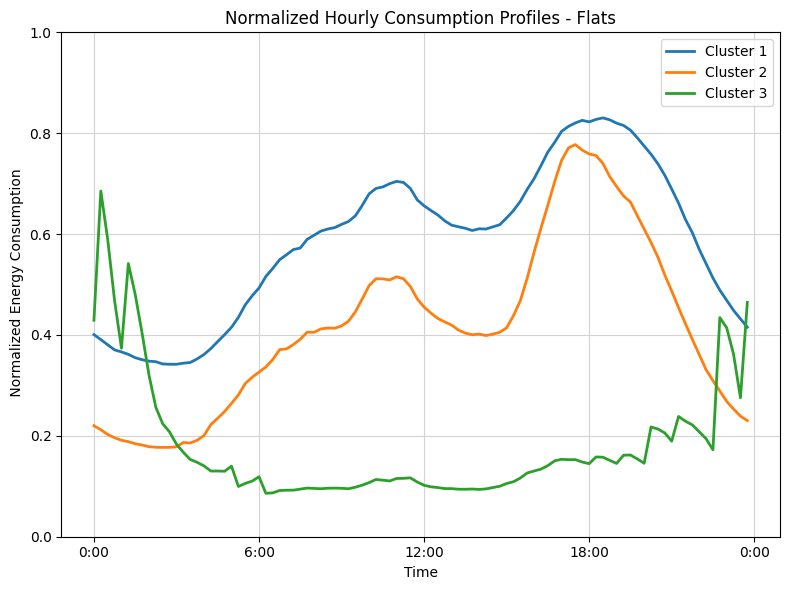

In [44]:
# Plot the clustered mean time series for each cluster

labels = ['0:00','6:00','12:00','18:00','0:00']

colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

n_clusters = len(np.unique(clusters_train))

plt.figure(figsize=(8,6))
for cluster_idx in range(n_clusters):

    # Get all time series in this cluster
    cluster_data = train_data[clusters_train == cluster_idx]
    cluster_indices = np.where(clusters_train == cluster_idx)[0]    

    # Calculate the mean time series for the cluster
    mean_time_series = np.mean(cluster_data, axis=0)
    
    # Plot the mean time series
    cluster_no = cluster_idx+1
    plt.plot(range(1,97), mean_time_series.ravel(), 
            label= f'Cluster {cluster_no}',
            linewidth =2, color=colors[cluster_idx])
    
# Plot settings
plt.title(f'Normalized Hourly Consumption Profiles - {building_type.capitalize()}s')
plt.xlabel("Time")
plt.ylabel(" Normalized Energy Consumption")
plt.ylim(0,1)
plt.xticks(range(1,120,24),labels=labels)
plt.tight_layout()
plt.grid(True, color = 'lightgray')
plt.legend(
loc='upper right',
bbox_to_anchor=(1, 1),
ncol=1,
fontsize='medium'
)
plt.savefig(
f"{project_root}/Results/{dataset}/Plots/Cluster/HourlyAveraged_KMeans_{building_type}.png",
bbox_inches='tight'
)
plt.show()

In [45]:
# Cluster summary statistics

dataset_summary_stats_df = pl.read_csv(f"{project_root}/DATA/{dataset}/dataset_summary_stats.csv")

dataset_summary_stats_df = dataset_summary_stats_df.with_columns(
    pl.col("file_id")
      .cast(pl.Utf8)
      .str.strip_chars()
      .str.to_lowercase()
      .alias("resident_id")
)

result_df = result_df.join(
    dataset_summary_stats_df.select([
        "resident_id",
        "bruttolastgang_kwh_sum",
        "average_daily_consumption"
    ]),
    on="resident_id",
    how="left"
)
result_df = result_df.select([
    "resident_id",
    "cluster",
    "bruttolastgang_kwh_sum",
    "average_daily_consumption"  
])

cluster_summary = result_df.group_by("cluster").agg([
    pl.count("resident_id").alias("num_households"),
    pl.mean("bruttolastgang_kwh_sum").alias("avg_yearly_consumption [kWh]").round(2),
    pl.mean("average_daily_consumption").alias("avg_daily_consumption [kWh]").round(2)
]).sort("cluster")

# Compute overall averages
overall_yearly_avg = round(result_df["bruttolastgang_kwh_sum"].mean(),2)
overall_seasonal_avg = round(result_df['average_daily_consumption'].mean(),2)

cluster_summary = cluster_summary.with_columns([
    pl.col("cluster").cast(pl.Utf8)
])
summary_row = pl.DataFrame({
    "cluster": ["Combined"], 
    "num_households": [result_df["resident_id"].n_unique()],
    "avg_yearly_consumption [kWh]": [overall_yearly_avg],
    "avg_daily_consumption [kWh]": [overall_seasonal_avg]
})

# Ensure dtypes match for concatenation
summary_row = summary_row.with_columns([
    pl.col("cluster").cast(cluster_summary["cluster"].dtype),
    pl.col("num_households").cast(cluster_summary["num_households"].dtype)
])

# Concatenate the summary row to the cluster summary
final_summary = pl.concat([cluster_summary, summary_row])

print(final_summary)

shape: (4, 4)
┌──────────┬────────────────┬──────────────────────────────┬─────────────────────────────┐
│ cluster  ┆ num_households ┆ avg_yearly_consumption [kWh] ┆ avg_daily_consumption [kWh] │
│ ---      ┆ ---            ┆ ---                          ┆ ---                         │
│ str      ┆ u32            ┆ f64                          ┆ f64                         │
╞══════════╪════════════════╪══════════════════════════════╪═════════════════════════════╡
│ 1        ┆ 317            ┆ 2037.77                      ┆ 5.55                        │
│ 2        ┆ 437            ┆ 1635.06                      ┆ 4.46                        │
│ 3        ┆ 47             ┆ 2734.44                      ┆ 7.45                        │
│ Combined ┆ 801            ┆ 1858.94                      ┆ 5.07                        │
└──────────┴────────────────┴──────────────────────────────┴─────────────────────────────┘


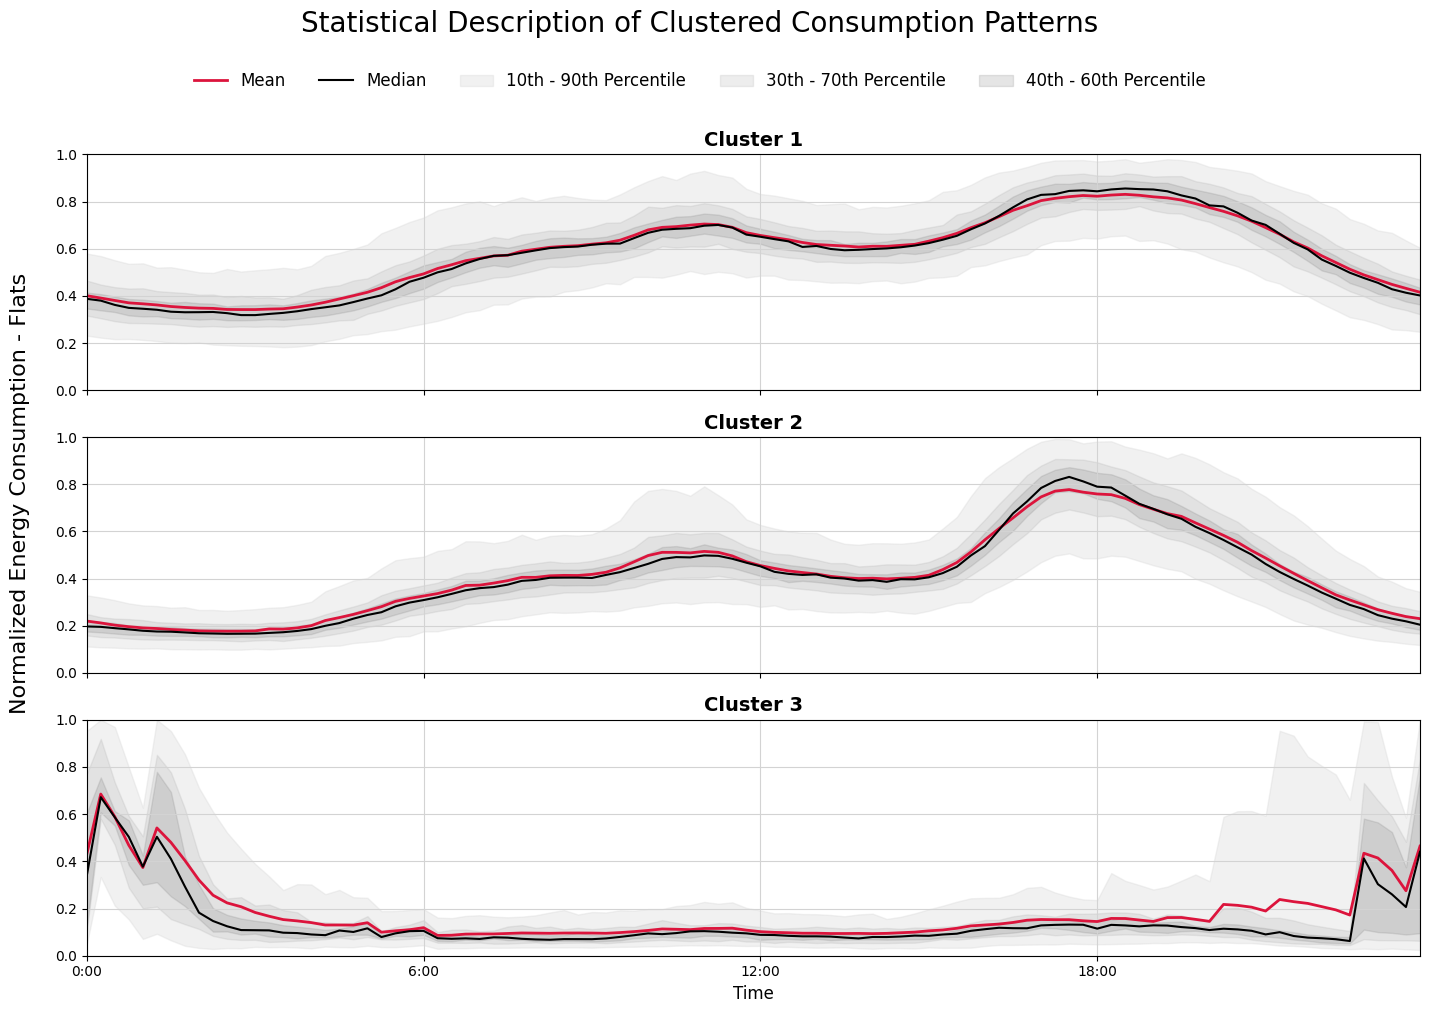

In [46]:
# Plot cluster percentiles for each cluster

clusters_train_stat = clusters_train + 1  # Shift cluster labels to start from 1

for i in range(number_of_clusters):

    i = i+1
    # Select samples for the current cluster
    cluster_data = train_data[clusters_train_stat == i]
    
    if cluster_data.shape[0] == 0:
        print(f"Warning: cluster {i} is empty, skipping.")
        continue  # Skip this cluster

plot_cluster_percentiles(project_root, train_data,clusters_train_stat,number_of_clusters, building_type, dataset, 'kMeans', 'all_features')

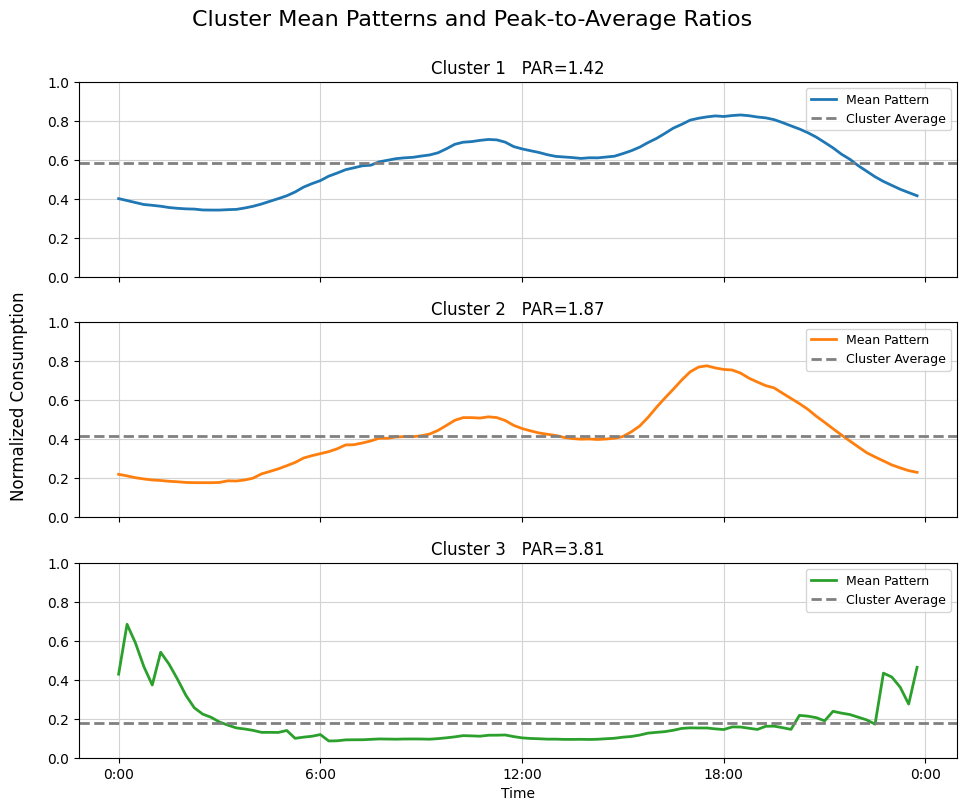

In [47]:
# Plot Mean Patterns and Peak-to-Average Ratios (PAR)

labels = ['0:00', '6:00', '12:00', '18:00', '0:00']
colors= ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728','#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


clusters = clusters_train + 1  # Cluster labels starting from 1
time_series_numeric = train_data.reshape((train_data.shape[0], train_data.shape[1]))

n_clusters_to_plot = np.unique(clusters)
n_clusters = len(n_clusters_to_plot)

fig, axes = plt.subplots(n_clusters, 1, figsize=(10, 2.8 * n_clusters), sharex=True)

if n_clusters == 1:
    axes = [axes]

for idx, cl in enumerate(sorted(n_clusters_to_plot)):
    cluster_idx = np.where(clusters == cl)[0]
    mean_time_series = time_series_numeric[cluster_idx].mean(axis=0)
    PAR_average = np.mean(mean_time_series)
    PAR_max = np.max(mean_time_series)

    ax = axes[idx]
    ax.plot(range(1,97), mean_time_series.ravel()[:96],
            label='Mean Pattern', linewidth=2, color=colors[cl-1])
    ax.axhline(PAR_average, color='grey', linestyle='--', linewidth=2, label='Cluster Average')
    ax.set_title(f"Cluster {cl}   PAR={PAR_max/PAR_average:.2f}",
                 loc='center', fontsize=12, color='black')
    ax.set_ylim(0, 1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.grid(color='lightgray', zorder=0)
    ax.legend(fontsize=9)
    if idx == n_clusters-1:
        ax.set_xlabel("Time")
        ax.set_xticks(range(1,120,24))
        ax.set_xticklabels(labels)
    else:
        ax.set_xticks([])

fig.suptitle("Cluster Mean Patterns and Peak-to-Average Ratios", fontsize=16,  y=0.96)
fig.text(0.038, 0.5, "Normalized Consumption", va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.06, 0, 1, 0.96])
plt.savefig(
    f"{project_root}/Results/{dataset}/Plots/Cluster/PAR_KMeans_{building_type}.png",
    bbox_inches='tight'
)
plt.show()